# 03 (revised config) — Compare candidates on notebook 02's saved splits

Notebook 02 is preliminary baseline work. We reuse its completed logistic-regression results rather than train them again. New candidates use **exactly the outer row assignments saved by 02**; no outer folds are generated here. The reserved test set is never read.

The older 03 experiment used different saved folds, with no documented experimental reason for changing them. Its scores remain historical results and are not mixed into this controlled comparison.

Run cells in order with the project kernel. By default this notebook loads results only. To train missing candidates, list their keys in `TRAIN_MODELS` and rerun the training cell. Progress appears in the notebook. Completed matching candidates are reused. Tree training can take many hours.

**Configurations:** reuse text-only logistic regression (30,000 terms) and A2 logistic regression (30,000 terms) from 02. Add A2 logistic regression, LightGBM and XGBoost with the 2,000-term limit used in 03. The extra 30,000-term A2 reference makes the vocabulary change visible. All logistic pipelines use 02's C grid `[0.1, 0.3, 1.0]`; tree grids retain 03's settings. A2 means raw fields, engineered flags/salary/country, writing style and TF-IDF. No lexicon block is added.

New candidates use 3 grouped inner folds, seed 42 and the same inner-seed rule as 02, PR-AUC tuning, and an inner out-of-fold F1 cutoff. Exact historical inner assignments were not saved by 02; reusing the same software environment as that run is necessary to reproduce them. The baseline files also lack a historical source/package manifest: we validate their folds and predictions against today's data, but cannot retroactively prove their original code versions. This limitation is recorded in the new manifest.

In [1]:
import hashlib
import importlib.metadata
import json
from pathlib import Path
import sys
import tempfile
from joblib import Memory
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/evaluation.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.features import build_inputs, logistic_pipeline, FEATURE_SETS
from src.evaluation import cross_validate, validate_folds, fold_signature, score_summary, summarise, paired_comparison
from src.model_comparison import model_spec

REPORT_DIR = ROOT / 'reports/model_comparison_revised'
PREDICTION_DIR = ROOT / 'data/processed/model_comparison_revised'
# Choose only candidates you want to train; [] reads existing results without fitting.
TRAIN_MODELS = ['logreg_a2_2k', 'lightgbm_a2_2k', 'xgboost_a2_2k']
# Example: TRAIN_MODELS = ['logreg_a2_2k', 'lightgbm_a2_2k', 'xgboost_a2_2k']
THREADS = 2
INNER_SPLITS = 3
SEED = 42
C_GRID = {'model__C': [0.1, 0.3, 1.0]}
BASELINES = {'logreg_text_30k': 'logreg_tf_idf_only', 'logreg_a2_30k': 'logreg_a2'}
CANDIDATES = ['logreg_a2_2k', 'lightgbm_a2_2k', 'xgboost_a2_2k']
NAMES = {'logreg_text_30k': '02: text-only logistic (30k)',
         'logreg_a2_30k': '02: A2 logistic (30k)',
         'logreg_a2_2k': 'Revised: A2 logistic (2k)',
         'lightgbm_a2_2k': 'Revised: A2 LightGBM (2k)',
         'xgboost_a2_2k': 'Revised: A2 XGBoost (2k)'}

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print('Training enabled for:', TRAIN_MODELS or 'none — load saved results only')

Training enabled for: ['logreg_a2_2k', 'lightgbm_a2_2k', 'xgboost_a2_2k']


## 1. Recover and validate notebook 02's exact outer folds

Read only training data. Match saved job IDs and group IDs, check disjoint groups, and verify every fold signature against the baseline score tables. Fail rather than silently create replacement splits.

In [2]:
train_path = ROOT / 'data/processed/d1_train.csv'
assignment_path = ROOT / 'data/processed/model_cv_assignments.csv'
train = pd.read_csv(train_path)
assert train.job_id.is_unique
X = build_inputs(train)
y, groups = train.fraudulent.to_numpy(), train.group_id.to_numpy()
assignments = pd.read_csv(assignment_path)
positions = pd.Series(np.arange(len(train)), index=train.job_id)
folds = []
for (repeat, fold), rows in assignments.groupby(['repeat', 'fold'], sort=True):
    if not rows.job_id.is_unique or not rows.job_id.isin(positions.index).all():
        raise ValueError('Invalid job IDs in the saved assignments.')
    val = np.sort(positions.loc[rows.job_id].to_numpy())
    saved_groups = rows.set_index('job_id').group_id
    if not np.array_equal(saved_groups.loc[train.iloc[val].job_id].to_numpy(), groups[val]):
        raise ValueError('Group IDs differ from notebook 02.')
    fit = np.setdiff1d(np.arange(len(train)), val)
    folds.append((int(repeat), int(fold), fit, val))
folds = validate_folds(folds, y, groups)
expected = {(r, f): fold_signature(y, groups, fit, val) for r, f, fit, val in folds}

def validate_scores(scores):
    if scores.duplicated(['repeat', 'fold']).any():
        raise ValueError('Duplicate score rows.')
    actual = {(int(s.repeat), int(s.fold)): s.fold_signature for s in scores.itertuples()}
    if actual != expected:
        raise ValueError('Scores do not match the exact notebook 02 folds and current training rows.')

RESULTS = {}
for key, stem in BASELINES.items():
    scores = pd.read_csv(ROOT / f'reports/tables/model_{stem}_fold_scores.csv')
    validate_scores(scores)
    predictions = pd.read_csv(ROOT / f'data/processed/model_{stem}_oof.csv')
    if predictions.duplicated(['repeat', 'job_id']).any() or len(predictions) != len(train) * len({r for r, *_ in folds}):
        raise ValueError('Baseline predictions are incomplete or duplicated.')
    # Recompute each score from saved probabilities and saved thresholds; no training.
    for r, f, fit, val in folds:
        batch = predictions[predictions.repeat == r].set_index('job_id')
        p = batch.loc[train.iloc[val].job_id, 'probability'].to_numpy()
        row = scores[(scores.repeat == r) & (scores.fold == f)].iloc[0]
        measured = score_summary(y[val], p, threshold=row.threshold)
        for metric in ['pr_auc', 'precision', 'recall', 'f1']:
            if not np.isclose(measured[metric], row[metric]):
                raise ValueError(f'{key}: saved {metric} does not match its predictions.')
    RESULTS[key] = scores
print(f'Validated {len(folds)} saved outer folds on {len(train):,} ads. Reused both 02 baselines.')
display(pd.DataFrame({NAMES[k]: summarise(v, k) for k, v in RESULTS.items()}).T.round(3))

Validated 25 saved outer folds on 14,439 ads. Reused both 02 baselines.


,pr_auc,roc_auc,precision,recall,f1,share_flagged,false_positive_rate,precision_at_budget,recall_at_budget,precision_top5pct,recall_top5pct,pr_auc_sd
02: text-only logistic (30k),0.601,0.919,0.624,0.516,0.550,0.043,0.019,0.546,0.568,0.546,0.568,0.085
02: A2 logistic (30k),0.605,0.932,0.611,0.535,0.566,0.043,0.018,0.559,0.581,0.559,0.581,0.094


## 2. Train only explicitly selected missing candidates

Each new candidate is cached with its own data, code, fold, settings and environment fingerprints. A changed fingerprint raises an error; choose a new report folder for a different experiment. Partial folds are saved for inspection; interrupted candidates restart. Baseline source-file fingerprints are recorded now to detect later changes, not as proof of the historical training environment. Restart the kernel after editing source files.

Local prerequisite check found that LightGBM cannot currently load because the macOS OpenMP library `libomp.dylib` is missing. Its Python package is installed, but the native runtime must be available before selecting LightGBM for training. Load-only comparison and the imported baselines do not require loading LightGBM.


In [3]:
def candidate_spec(key, memory=None):
    if key == 'logreg_a2_2k':
        pipe = logistic_pipeline(FEATURE_SETS['A2'], tfidf_max_features=2000)
        pipe.set_params(memory=memory, model__random_state=SEED)
        return pipe, C_GRID
    mapping = {'lightgbm_a2_2k': 'lightgbm_a2', 'xgboost_a2_2k': 'xgboost_a2'}
    pipe, grid, _ = model_spec(mapping[key], memory=memory, threads=THREADS)
    return pipe, grid

if INNER_SPLITS != 3 or SEED != 42:
    raise ValueError('Reusing notebook 02 baselines requires INNER_SPLITS=3 and SEED=42.')
if set(TRAIN_MODELS) - set(CANDIDATES):
    raise ValueError('TRAIN_MODELS must contain only keys from CANDIDATES.')
context = {
    'training_sha256': sha(train_path), 'assignments_sha256': sha(assignment_path),
    'outer_signatures': {f'{r}:{f}': value for (r, f), value in expected.items()},
    'source_sha256': {name: sha(ROOT / 'src' / name) for name in ['features.py', 'evaluation.py', 'model_comparison.py']},
    'baseline_sha256': {str(path.relative_to(ROOT)): sha(path) for stem in BASELINES.values()
                       for path in [ROOT / f'reports/tables/model_{stem}_fold_scores.csv',
                                    ROOT / f'data/processed/model_{stem}_oof.csv']},
    'versions': {p: importlib.metadata.version(p) for p in ['numpy', 'pandas', 'scikit-learn', 'lightgbm', 'xgboost']},
    'seed': SEED, 'inner_splits': INNER_SPLITS, 'review_share': 0.05,
    'threshold': 'inner OOF maximum F1',
    'baseline_provenance': 'Imported from notebook 02; original source/package manifest unavailable. Outer folds and prediction metrics verified.'
}
for key in CANDIDATES:
    if key not in TRAIN_MODELS and not (REPORT_DIR / f'{key}_complete.json').exists():
        print(f'Pending: {key}. Add its key to TRAIN_MODELS to train it.')
        continue
    pipe, grid = candidate_spec(key)
    manifest = {**context, 'model': key, 'grid': grid, 'estimator': repr(pipe), 'threads': THREADS}
    plan_path = REPORT_DIR / f'{key}_plan.json'
    complete_path = REPORT_DIR / f'{key}_complete.json'
    score_path = REPORT_DIR / f'{key}_fold_scores.csv'
    if plan_path.exists() and json.loads(plan_path.read_text()) != manifest:
        raise ValueError(f'{key}: cached experiment differs. Choose a new REPORT_DIR and PREDICTION_DIR.')
    if complete_path.exists():
        completion = json.loads(complete_path.read_text())
        if not plan_path.exists() or sha(score_path) != completion['scores_sha256']:
            raise ValueError(f'{key}: incomplete or changed cached results.')
        scores = pd.read_csv(score_path)
        validate_scores(scores)
        RESULTS[key] = scores
        print(f'Reused completed {key}')
        continue
    if key not in TRAIN_MODELS:
        print(f'Pending: {key}. Add its key to TRAIN_MODELS to train it.')
        continue
    REPORT_DIR.mkdir(parents=True, exist_ok=True)
    PREDICTION_DIR.mkdir(parents=True, exist_ok=True)
    plan_path.write_text(json.dumps(manifest, indent=2))
    assignments.to_csv(REPORT_DIR / 'outer_assignments.csv', index=False)
    print(f'\nTraining {NAMES[key]}', flush=True)
    checkpoints, predictions = [], []
    with tempfile.TemporaryDirectory(prefix='bt4012_revised_') as cache:
        memory = Memory(cache, verbose=0)
        pipe, grid = candidate_spec(key, memory)
        def progress(row, val, probabilities):
            checkpoints.append({**row, 'selected_params': json.dumps(row['selected_params'], sort_keys=True)})
            pd.DataFrame(checkpoints).to_csv(score_path, index=False)
            predictions.append(pd.DataFrame({'repeat': row['repeat'], 'fold': row['fold'],
                'job_id': train.iloc[val].job_id.to_numpy(), 'probability': probabilities,
                'threshold': row['threshold']}))
            pd.concat(predictions, ignore_index=True).to_csv(PREDICTION_DIR / f'{key}_predictions.csv', index=False)
            memory.clear(warn=False)
        with threadpool_limits(limits=THREADS):
            scores, _ = cross_validate(lambda: pipe, X, y, groups, folds=folds,
                param_grid=grid, inner_splits=INNER_SPLITS, seed=SEED, on_fold=progress)
        candidates = scores.attrs['inner_candidates'].copy()
        candidates['params'] = candidates.params.map(lambda v: json.dumps(v, sort_keys=True))
        candidates.to_csv(REPORT_DIR / f'{key}_inner_settings.csv', index=False)
    validate_scores(scores)
    complete_path.write_text(json.dumps({'model': key, 'folds': len(scores), 'scores_sha256': sha(score_path)}, indent=2))
    RESULTS[key] = scores


Training Revised: A2 logistic (2k)
Repeat 1, fold 1: PR-AUC 0.582, cutoff 0.743, settings {'model__C': 1.0}
Repeat 1, fold 2: PR-AUC 0.537, cutoff 0.876, settings {'model__C': 1.0}
Repeat 1, fold 3: PR-AUC 0.618, cutoff 0.670, settings {'model__C': 1.0}
Repeat 1, fold 4: PR-AUC 0.610, cutoff 0.859, settings {'model__C': 1.0}
Repeat 1, fold 5: PR-AUC 0.370, cutoff 0.808, settings {'model__C': 1.0}
Repeat 2, fold 1: PR-AUC 0.330, cutoff 0.846, settings {'model__C': 1.0}
Repeat 2, fold 2: PR-AUC 0.601, cutoff 0.785, settings {'model__C': 1.0}
Repeat 2, fold 3: PR-AUC 0.660, cutoff 0.683, settings {'model__C': 1.0}
Repeat 2, fold 4: PR-AUC 0.580, cutoff 0.785, settings {'model__C': 1.0}
Repeat 2, fold 5: PR-AUC 0.583, cutoff 0.821, settings {'model__C': 1.0}
Repeat 3, fold 1: PR-AUC 0.518, cutoff 0.764, settings {'model__C': 1.0}
Repeat 3, fold 2: PR-AUC 0.577, cutoff 0.816, settings {'model__C': 1.0}
Repeat 3, fold 3: PR-AUC 0.720, cutoff 0.804, settings {'model__C': 1.0}
Repeat 3, fold 

## 3. Compare completed results without fitting

All numbers below are means of the same outer-fold metrics, including the imported 02 baselines. Pending candidates are explicitly listed. Precision and recall use training-chosen cutoffs; the top-5% columns use a separate fixed review-budget policy. PR-AUC is ranking performance, not accuracy.

Comparison status: COMPLETE


,pr_auc,precision,recall,f1,precision_top5pct,recall_top5pct
Revised: A2 LightGBM (2k),0.614,0.587,0.543,0.535,0.537,0.558
02: A2 logistic (30k),0.605,0.611,0.535,0.566,0.559,0.581
02: text-only logistic (30k),0.601,0.624,0.516,0.550,0.546,0.568
Revised: A2 XGBoost (2k),0.564,0.549,0.483,0.497,0.493,0.513
Revised: A2 logistic (2k),0.552,0.559,0.513,0.518,0.536,0.557


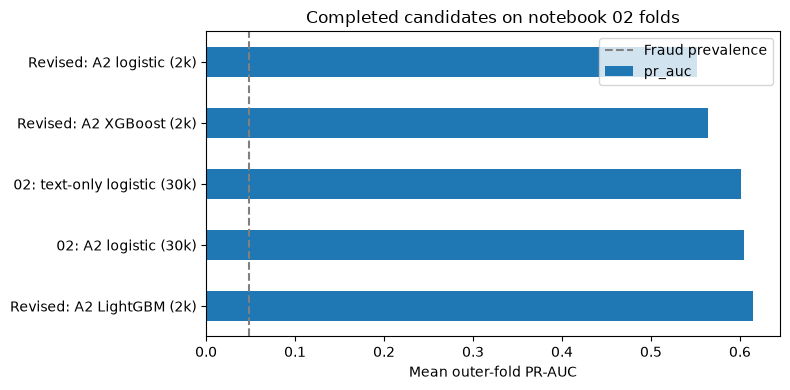

In [4]:
missing = [key for key in CANDIDATES if key not in RESULTS]
print('Comparison status:', 'COMPLETE' if not missing else f'PARTIAL — pending {missing}')
summary = pd.DataFrame({NAMES[k]: summarise(v, k) for k, v in RESULTS.items()}).T
summary = summary.sort_values('pr_auc', ascending=False)
display(summary[['pr_auc', 'precision', 'recall', 'f1', 'precision_top5pct', 'recall_top5pct']].round(3))
ax = summary.pr_auc.plot.barh(figsize=(8, 4), xlabel='Mean outer-fold PR-AUC', title='Completed candidates on notebook 02 folds')
ax.axvline(y.mean(), color='grey', linestyle='--', label='Fraud prevalence')
ax.legend()
plt.tight_layout()
plt.show()
REPORT_DIR.mkdir(parents=True, exist_ok=True)
summary.to_csv(REPORT_DIR / 'comparison_summary.csv')

## 4. Paired differences: is an improvement supported?

Compare each completed candidate against the text-only baseline. Compare the 2,000-term A2 models with each other to isolate the algorithm, and compare A2 logistic 2k with A2 logistic 30k to examine vocabulary size. These approximate intervals account for overlapping training data, but are exploratory and not adjusted for multiple comparisons. An interval crossing zero does not establish a ranking improvement. No final fitted model is selected or exported here.

In [5]:
comparisons = []
for key in RESULTS:
    references = ['logreg_text_30k']
    if key in ['lightgbm_a2_2k', 'xgboost_a2_2k'] and 'logreg_a2_2k' in RESULTS:
        references.append('logreg_a2_2k')
    if key == 'logreg_a2_2k':
        references.append('logreg_a2_30k')
    for reference in references:
        if key == reference:
            continue
        difference = paired_comparison(RESULTS[key], RESULTS[reference], metric='pr_auc')
        comparisons.append({'candidate': NAMES[key], 'reference': NAMES[reference], **difference})
paired = pd.DataFrame(comparisons)
display(paired.round(3))
paired.to_csv(REPORT_DIR / 'paired_differences.csv', index=False)
print('The reserved test set has not been opened. Do not treat the highest mean as a proven winner.')

,candidate,reference,mean_diff,se,low,high,share_folds_a_better
0,02: A2 logistic (30k),02: text-only logistic (30k),0.004,0.046,-0.088,0.096,0.48
1,Revised: A2 logistic (2k),02: text-only logistic (30k),-0.049,0.050,-0.150,0.051,0.28
2,Revised: A2 logistic (2k),02: A2 logistic (30k),-0.053,0.024,-0.101,-0.004,0.04
3,Revised: A2 LightGBM (2k),02: text-only logistic (30k),0.013,0.051,-0.088,0.114,0.52
4,Revised: A2 LightGBM (2k),Revised: A2 logistic (2k),0.062,0.045,-0.027,0.152,0.76
5,Revised: A2 XGBoost (2k),02: text-only logistic (30k),-0.038,0.057,-0.152,0.077,0.36
6,Revised: A2 XGBoost (2k),Revised: A2 logistic (2k),0.012,0.065,-0.118,0.141,0.32


The reserved test set has not been opened. Do not treat the highest mean as a proven winner.
